# 04 - Zonal Statistics: Build the Tabular Feature Table

Aggregates every raster dataset onto the 1km grid from notebook 03, one row per grid cell. This is the tabular feature table the MLP branch of the model reads from (the CNN branch gets its input separately, as Sentinel-2 patches per cell - a later notebook).

Aggregation rule: **mean** for continuous variables (climate, soil, elevation, slope), **majority** (mode) for categorical ones (GAEZ suitability class, land cover).

This is the slowest notebook so far - CHIRPS alone means looping `zonal_stats` over 60 files. Expect it to take a while.

In [1]:
# add scripts/download to sys.path so we can `from common import ...`
import os, sys
from pathlib import Path

NOTEBOOK_DIR = Path(os.path.abspath("."))
if NOTEBOOK_DIR.name != "preprocessing":
    NOTEBOOK_DIR = NOTEBOOK_DIR / "scripts" / "preprocessing"
os.chdir(NOTEBOOK_DIR)

PROJECT_ROOT = NOTEBOOK_DIR.parents[1]
DOWNLOAD_DIR = PROJECT_ROOT / "scripts" / "download"
if str(DOWNLOAD_DIR) not in sys.path:
    sys.path.insert(0, str(DOWNLOAD_DIR))

print("cwd:", os.getcwd())

cwd: D:\Softwares\AnacondaProjects\GeoSuitability_AI_Analytics\scripts\preprocessing


## 1. Load the grid

In [2]:
import geopandas as gpd
import pandas as pd

from common import RAW_DIR, PROCESSED_DIR, ensure_dir, get_logger

log = get_logger("zonal_stats")

GRID_PATH = PROCESSED_DIR / "grid" / "grid_1km.gpkg"
OUT_DIR = PROCESSED_DIR / "features"
OUT_PATH = OUT_DIR / "tabular_features.csv"

grid = gpd.read_file(GRID_PATH)
grid_4326 = grid.to_crs("EPSG:4326")  # WorldClim/CHIRPS/SoilGrids/GAEZ/WorldCover are all lat/lon
print(f"{len(grid)} grid cells loaded")

features = pd.DataFrame({"grid_id": grid["grid_id"]})

9333 grid cells loaded


## 2. Helpers

In [3]:
from rasterstats import zonal_stats

# all_touched=True matters a lot here: several source rasters (WorldClim ~4.6km,
# GAEZ ~9km) are coarser than our 1km grid cells. rasterstats default only counts
# a pixel if its *center* falls inside the polygon - since our cells are much
# smaller than those pixels, most cells would get 0 matching pixels and come back
# as None. all_touched counts any pixel the cell geometry overlaps at all, which
# is what we actually want when the cell is the small one.


def add_mean(raster_path, column, geometries=grid_4326.geometry, nodata=None):
    """Zonal mean of one raster's band 1 onto `features[column]`, matched by row order."""
    stats = zonal_stats(geometries, str(raster_path), stats=["mean"], nodata=nodata, all_touched=True)
    features[column] = [s["mean"] for s in stats]
    log.info("  %s: %d/%d cells got a value", column, features[column].notna().sum(), len(features))


def add_majority(raster_path, column, geometries=grid_4326.geometry, nodata=None):
    """Zonal majority (mode) class of one raster's band 1 onto `features[column]`."""
    stats = zonal_stats(geometries, str(raster_path), stats=["majority"], nodata=nodata, all_touched=True)
    features[column] = [s["majority"] for s in stats]
    log.info("  %s: %d/%d cells got a value", column, features[column].notna().sum(), len(features))

## 3. WorldClim - temperature & precipitation baseline

In [4]:
print("WorldClim...")
wc_dir = RAW_DIR / "worldclim"
add_mean(wc_dir / "wc2.1_2.5m_bio_1.tif", "bio1_temp_mean_c")
add_mean(wc_dir / "wc2.1_2.5m_bio_12.tif", "bio12_precip_annual_mm")
add_mean(wc_dir / "wc2.1_2.5m_bio_15.tif", "bio15_precip_seasonality")

WorldClim...


[zonal_stats]   bio1_temp_mean_c: 9333/9333 cells got a value
[zonal_stats]   bio12_precip_annual_mm: 9333/9333 cells got a value
[zonal_stats]   bio15_precip_seasonality: 9333/9333 cells got a value


## 4. CHIRPS - multi-year rainfall stats

In [5]:
print("CHIRPS (cropping each file to the Banten bbox before zonal_stats - much faster than")
print("reading the full global raster 60 times)...")
import rasterio
from rasterio.windows import from_bounds

chirps_dir = RAW_DIR / "chirps"
CHIRPS_NODATA = -9999  # CHIRPS files don't declare nodata in their own metadata (src.nodata is None),
                        # but -9999 is the documented sentinel value used for missing pixels

# small buffer so all_touched polygons right at the AOI edge still see their full
# neighborhood of pixels, not just whatever the crop window happens to include
CHIRPS_BUFFER_DEG = 0.1
bbox = grid_4326.total_bounds
bbox_buffered = (
    bbox[0] - CHIRPS_BUFFER_DEG, bbox[1] - CHIRPS_BUFFER_DEG,
    bbox[2] + CHIRPS_BUFFER_DEG, bbox[3] + CHIRPS_BUFFER_DEG,
)

rows = []
for year in range(2020, 2025):
    for month in range(1, 13):
        path = chirps_dir / f"chirps-v2.0.{year}.{month:02d}.tif"
        if not path.exists():
            log.warning("Missing CHIRPS file: %s", path)
            continue
        with rasterio.open(path) as src:
            window = from_bounds(*bbox_buffered, transform=src.transform).round_lengths().round_offsets()
            data = src.read(1, window=window)
            window_transform = src.window_transform(window)
            # (ignore src.nodata here - CHIRPS files leave it unset, see CHIRPS_NODATA above)
        stats = zonal_stats(
            grid_4326.geometry, data, affine=window_transform, stats=["mean"],
            all_touched=True, nodata=CHIRPS_NODATA,
        )
        for grid_id, s in zip(grid_4326["grid_id"], stats):
            rows.append({"grid_id": grid_id, "year": year, "month": month, "rain_mm": s["mean"]})

chirps_long = pd.DataFrame(rows)
annual_totals = chirps_long.groupby(["grid_id", "year"])["rain_mm"].sum().reset_index()
chirps_summary = annual_totals.groupby("grid_id")["rain_mm"].agg(
    chirps_annual_mean_mm="mean", chirps_annual_std_mm="std"
)
features = features.merge(chirps_summary, on="grid_id", how="left")
log.info("CHIRPS done: %d cells with rainfall stats", features["chirps_annual_mean_mm"].notna().sum())

CHIRPS (cropping each file to the Banten bbox before zonal_stats - much faster than
reading the full global raster 60 times)...


[zonal_stats] CHIRPS done: 9333 cells with rainfall stats


## 5. SoilGrids - soil properties

In [6]:
print("SoilGrids...")
sg_dir = RAW_DIR / "soilgrids"
add_mean(sg_dir / "phh2o_0-5cm_mean.tif", "soil_ph")
add_mean(sg_dir / "soc_0-5cm_mean.tif", "soil_soc")
add_mean(sg_dir / "nitrogen_0-5cm_mean.tif", "soil_nitrogen")
add_mean(sg_dir / "clay_0-5cm_mean.tif", "soil_clay_pct")
add_mean(sg_dir / "sand_0-5cm_mean.tif", "soil_sand_pct")
add_mean(sg_dir / "cec_0-5cm_mean.tif", "soil_cec")
add_mean(sg_dir / "bdod_0-5cm_mean.tif", "soil_bulk_density")

SoilGrids...


[zonal_stats]   soil_ph: 7894/9333 cells got a value
[zonal_stats]   soil_soc: 7898/9333 cells got a value
[zonal_stats]   soil_nitrogen: 7894/9333 cells got a value
[zonal_stats]   soil_clay_pct: 7894/9333 cells got a value
[zonal_stats]   soil_sand_pct: 7894/9333 cells got a value
[zonal_stats]   soil_cec: 7894/9333 cells got a value
[zonal_stats]   soil_bulk_density: 7898/9333 cells got a value


## 6. DEM - elevation & slope

In [7]:
print("DEM (elevation + slope)...")
import numpy as np
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling

dem_path = RAW_DIR / "dem" / "cop30_banten.tif"
TARGET_CRS = grid.crs  # UTM 48S, so gradients come out in meters

with rasterio.open(dem_path) as src:
    dem_nodata = src.nodata  # capture before the file closes, don't rely on reading it afterward
    transform, width, height = calculate_default_transform(
        src.crs, TARGET_CRS, src.width, src.height, *src.bounds
    )
    dem_utm = np.empty((height, width), dtype=np.float32)
    reproject(
        source=rasterio.band(src, 1),
        destination=dem_utm,
        src_transform=src.transform,
        src_crs=src.crs,
        dst_transform=transform,
        dst_crs=TARGET_CRS,
        resampling=Resampling.bilinear,
    )

# elevation, straight zonal mean in the grid's native (UTM) CRS
elev_stats = zonal_stats(grid.geometry, dem_utm, affine=transform, stats=["mean"], nodata=dem_nodata, all_touched=True)
features["elevation_mean_m"] = [s["mean"] for s in elev_stats]

# slope in degrees from the gradient of the reprojected (meter-unit) DEM
pixel_size = transform.a  # square pixels, so .a == -.e in magnitude
dzdy, dzdx = np.gradient(dem_utm, pixel_size)
slope_deg = np.degrees(np.arctan(np.sqrt(dzdx**2 + dzdy**2)))
slope_stats = zonal_stats(grid.geometry, slope_deg, affine=transform, stats=["mean"], nodata=dem_nodata, all_touched=True)
features["slope_mean_deg"] = [s["mean"] for s in slope_stats]

log.info(
    "DEM done: elevation for %d cells, slope for %d cells",
    features["elevation_mean_m"].notna().sum(),
    features["slope_mean_deg"].notna().sum(),
)

DEM (elevation + slope)...


D:\Softwares\Anaconda\Miniconda\envs\geoai-suitability\Lib\site-packages\rasterstats\io.py:437: NodataWarning: Setting nodata to -999; specify nodata explicitly
  warnings.warn(
[zonal_stats] DEM done: elevation for 9315 cells, slope for 9315 cells


## 7. GAEZ v5 - crop suitability class

In [8]:
print("GAEZ v5 suitability - class (majority) and index (mean) per crop...")
gaez_dir = RAW_DIR / "gaez_v5"


def gaez_file(*candidates: str) -> Path:
    """Older runs of download_gaez.ipynb used different file-name labels - try a few."""
    for name in candidates:
        p = gaez_dir / name
        if p.exists():
            return p
    raise FileNotFoundError(f"None of {candidates} found in {gaez_dir}")


add_majority(gaez_file("suitability_class_rice_RCW.tif", "suitability_class_padi_RCW.tif"), "gaez_class_rice")
add_majority(gaez_file("suitability_class_maize_MZE.tif", "suitability_class_jagung_MZE.tif"), "gaez_class_maize")
add_majority(gaez_file("suitability_class_cassava_CSV.tif", "suitability_class_singkong_CSV.tif"), "gaez_class_cassava")
add_majority(gaez_file("suitability_class_soybean_SOY.tif", "suitability_class_kedelai_SOY.tif"), "gaez_class_soybean")

# continuous Index (0-10000) - much finer-grained than the Class above, needed to actually
# rank crops against each other (see 05_eda.ipynb SS11 for why: Class alone ties 83% of cells)
add_mean(gaez_file("suitability_index_rice_RCW.tif"), "gaez_index_rice")
add_mean(gaez_file("suitability_index_maize_MZE.tif"), "gaez_index_maize")
add_mean(gaez_file("suitability_index_cassava_CSV.tif"), "gaez_index_cassava")
add_mean(gaez_file("suitability_index_soybean_SOY.tif"), "gaez_index_soybean")

GAEZ v5 suitability - class (majority) and index (mean) per crop...


[zonal_stats]   gaez_class_rice: 9333/9333 cells got a value
[zonal_stats]   gaez_class_maize: 9333/9333 cells got a value
[zonal_stats]   gaez_class_cassava: 9333/9333 cells got a value
[zonal_stats]   gaez_class_soybean: 9333/9333 cells got a value
[zonal_stats]   gaez_index_rice: 9333/9333 cells got a value
[zonal_stats]   gaez_index_maize: 9333/9333 cells got a value
[zonal_stats]   gaez_index_cassava: 9333/9333 cells got a value
[zonal_stats]   gaez_index_soybean: 9333/9333 cells got a value


## 8. ESA WorldCover - land cover & cropland share

In [9]:
print("ESA WorldCover (mosaic 2 tiles, then majority land cover + % cropland)...")
from rasterio.merge import merge

wc_dir = RAW_DIR / "worldcover"
wc_tiles = sorted(wc_dir.glob("ESA_WorldCover_10m_*_Map.tif"))
srcs = [rasterio.open(t) for t in wc_tiles]
wc_mosaic, wc_transform = merge(srcs)
wc_crs = srcs[0].crs
wc_nodata = srcs[0].nodata  # 0 for WorldCover - must pass this explicitly, rasterstats
                             # defaults to -999 which overflows a uint8 array and crashes
for s in srcs:
    s.close()

wc_stats = zonal_stats(
    grid.to_crs(wc_crs).geometry, wc_mosaic[0], affine=wc_transform,
    stats=["majority"], categorical=True, nodata=wc_nodata, all_touched=True,
)
features["landcover_majority"] = [s["majority"] for s in wc_stats]

# WorldCover class 40 = cropland
cropland_pct = []
for s in wc_stats:
    total = sum(v for k, v in s.items() if isinstance(k, (int, float)))
    cropland = s.get(40, 0)
    cropland_pct.append(100 * cropland / total if total else None)
features["cropland_pct"] = cropland_pct

log.info("WorldCover done: land cover for %d cells", features["landcover_majority"].notna().sum())

ESA WorldCover (mosaic 2 tiles, then majority land cover + % cropland)...


[zonal_stats] WorldCover done: land cover for 9333 cells


## 9. Fill the SoilGrids coverage gap via spatial interpolation

SoilGrids has a real coverage gap over part of northeastern Banten (verified straight against ISRIC's own source VRT, not a bug in our download/crop step - see the notebook write-up for details). ~1439 of 9333 cells (~15%) come back with no soil values; about 43% of those are built-up land anyway, but a meaningful chunk (cropland + tree cover) is agriculturally relevant and needs a value.

Filling those with **spatial interpolation** from the nearest cells that do have real SoilGrids readings - linear interpolation over the grid's projected (UTM) coordinates, falling back to nearest-neighbor for the handful of edge cells outside the convex hull of valid points. Every interpolated row gets flagged in `soil_data_interpolated` so it stays traceable - these are estimated, not directly measured, and that distinction is preserved in the output rather than silently smoothed over.

In [10]:
print("Filling the SoilGrids gap via spatial interpolation...")
import numpy as np
from scipy.interpolate import griddata

SOIL_COLS = [
    "soil_ph", "soil_soc", "soil_nitrogen", "soil_clay_pct",
    "soil_sand_pct", "soil_cec", "soil_bulk_density",
]

# projected (UTM) centroids so distances are real meters, not degrees
centroids_utm = grid.geometry.centroid
coords = np.column_stack([centroids_utm.x.values, centroids_utm.y.values])

was_missing = features[SOIL_COLS[0]].isna().values.copy()
features["soil_data_interpolated"] = was_missing

for col in SOIL_COLS:
    # keep the untouched raw values around (with the original NaNs) so we can
    # compare before-vs-after later - only the plain `col` gets overwritten
    features[f"{col}_raw"] = features[col].copy()

    values = features[col].to_numpy(dtype=float, copy=True)  # copy=True - to_numpy() can return a read-only view
    valid = ~np.isnan(values)
    n_missing = (~valid).sum()
    if n_missing == 0:
        continue

    filled = griddata(coords[valid], values[valid], coords[~valid], method="linear")
    still_nan = np.isnan(filled)
    if still_nan.any():
        # points outside the convex hull of valid data - nearest-neighbor as a fallback
        filled[still_nan] = griddata(
            coords[valid], values[valid], coords[~valid][still_nan], method="nearest"
        )

    values[~valid] = filled
    features[col] = values
    log.info("  %s: interpolated %d cells", col, n_missing)

print(f"Done. {was_missing.sum()} cells now carry interpolated soil values (flagged in soil_data_interpolated).")

Filling the SoilGrids gap via spatial interpolation...


[zonal_stats]   soil_ph: interpolated 1439 cells
[zonal_stats]   soil_soc: interpolated 1435 cells
[zonal_stats]   soil_nitrogen: interpolated 1439 cells
[zonal_stats]   soil_clay_pct: interpolated 1439 cells
[zonal_stats]   soil_sand_pct: interpolated 1439 cells
[zonal_stats]   soil_cec: interpolated 1439 cells
[zonal_stats]   soil_bulk_density: interpolated 1435 cells


Done. 1439 cells now carry interpolated soil values (flagged in soil_data_interpolated).


## 10. Merge everything and save

In [11]:
ensure_dir(OUT_DIR)

full = grid[["grid_id", "row", "col", "lon", "lat"]].merge(features, on="grid_id", how="left")
full.to_csv(OUT_PATH, index=False)

print(f"Saved {OUT_PATH}")
print(f"  {len(full)} rows, {len(full.columns)} columns")
full.describe()

Saved D:\Softwares\AnacondaProjects\GeoSuitability_AI_Analytics\datasets\processed\features\tabular_features.csv
  9333 rows, 37 columns


,row,col,lon,lat,bio1_temp_mean_c,bio12_precip_annual_mm,bio15_precip_seasonality,chirps_annual_mean_mm,chirps_annual_std_mm,soil_ph,...,gaez_index_soybean,landcover_majority,cropland_pct,soil_ph_raw,soil_soc_raw,soil_nitrogen_raw,soil_clay_pct_raw,soil_sand_pct_raw,soil_cec_raw,soil_bulk_density_raw
count,9333.000000,9333.000000,9333.000000,9333.000000,9333.000000,9333.000000,9333.000000,9333.000000,9333.000000,9333.000000,...,9333.000000,9333.000000,9333.000000,7894.000000,7898.000000,7894.000000,7894.000000,7894.000000,7894.000000,7898.000000
mean,63.711561,111.134469,106.108932,-6.456295,25.151288,2949.495571,39.017321,3438.848072,580.841676,52.721407,...,1597.530921,19.217293,15.956388,52.444644,807.539827,419.419728,409.748335,217.633120,235.938297,107.504528
std,29.735672,35.442431,0.320281,0.269196,1.782467,733.907694,9.178219,757.793808,130.283880,1.335863,...,1011.120835,17.023966,23.401248,1.186544,216.540234,78.656615,46.993464,45.938632,32.519214,8.937669
min,0.000000,0.000000,105.104034,-7.033623,15.602750,1627.000000,18.668436,1692.451595,210.949321,47.560000,...,0.000000,10.000000,0.000000,47.560000,384.333333,231.333333,283.000000,110.000000,139.200000,59.000000
25%,37.000000,90.000000,105.917766,-6.698320,24.735834,2297.000000,32.928913,2697.596951,489.051111,51.850000,...,750.000000,10.000000,0.576730,51.720000,669.540000,357.670000,373.420000,183.060000,216.280000,103.040000
50%,62.000000,114.000000,106.134749,-6.471466,25.588333,3117.250000,40.104748,3681.170197,616.177888,52.560000,...,1525.000000,10.000000,4.902043,52.360000,758.860000,433.520000,407.490000,215.940000,236.960000,107.080000
75%,89.000000,136.000000,106.334158,-6.226079,26.319000,3365.500000,44.315643,4082.883632,674.936208,53.440000,...,2101.000000,30.000000,21.028428,53.000000,892.601630,470.660000,441.990000,249.480000,256.085217,111.040000
max,135.000000,185.000000,106.776360,-5.811233,27.382166,4400.000000,69.835556,5029.849386,1054.451871,58.440000,...,4988.000000,95.000000,100.000000,58.440000,1748.160000,763.320000,555.960000,362.600000,359.320000,134.333333


## 11. Visualize each dataset

One figure per source dataset, plotted on the grid, rather than a single mixed preview - makes it easier to sanity-check any one dataset without the others cluttering the view.

In [12]:
import matplotlib.pyplot as plt
import numpy as np

merged = grid.merge(features, on="grid_id", how="left")


def plot_columns(specs, ncols, suptitle, panel_size=(4.5, 4.5)):
    """specs: list of (column, title, cmap) tuples, or (column, title, cmap, categorical)
    for nominal/class-code columns that should not be shown on a continuous color scale."""
    n = len(specs)
    nrows = -(-n // ncols)  # ceil division
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel_size[0] * ncols, panel_size[1] * nrows))
    axes = np.atleast_1d(axes).flatten()

    for ax, spec in zip(axes, specs):
        col, title, cmap = spec[0], spec[1], spec[2]
        categorical = spec[3] if len(spec) > 3 else False
        merged.plot(
            column=col, cmap=cmap, legend=True, ax=ax, categorical=categorical,
            missing_kwds={"color": "lightgray"},
        )
        ax.set_title(title, fontsize=10)
        ax.axis("off")

    for ax in axes[len(specs):]:
        ax.axis("off")

    fig.suptitle(suptitle, fontsize=13)
    plt.tight_layout()
    plt.show()

### WorldClim

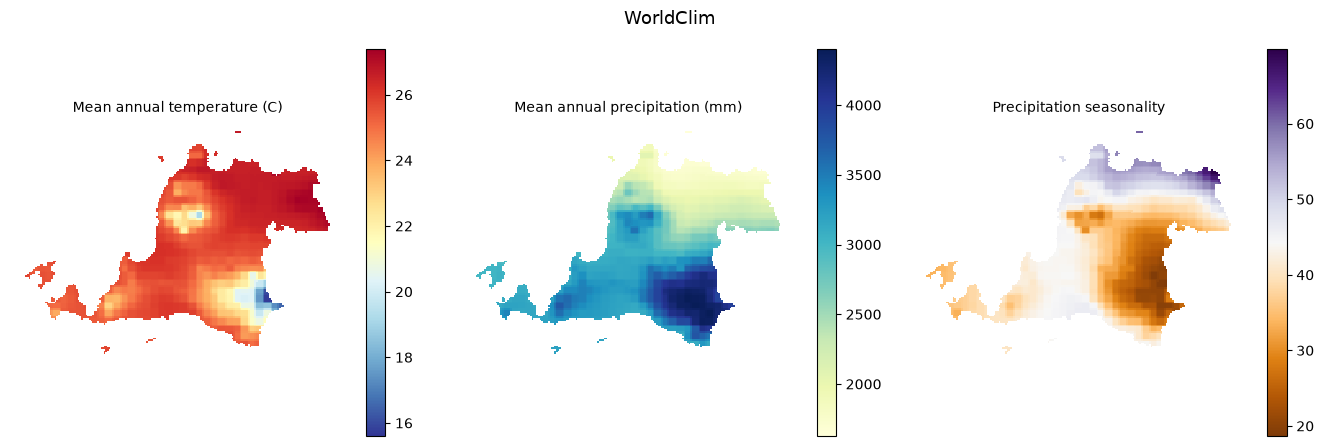

In [13]:
plot_columns(
    [
        ("bio1_temp_mean_c", "Mean annual temperature (C)", "RdYlBu_r"),
        ("bio12_precip_annual_mm", "Mean annual precipitation (mm)", "YlGnBu"),
        ("bio15_precip_seasonality", "Precipitation seasonality", "PuOr"),
    ],
    ncols=3, suptitle="WorldClim",
)

### CHIRPS

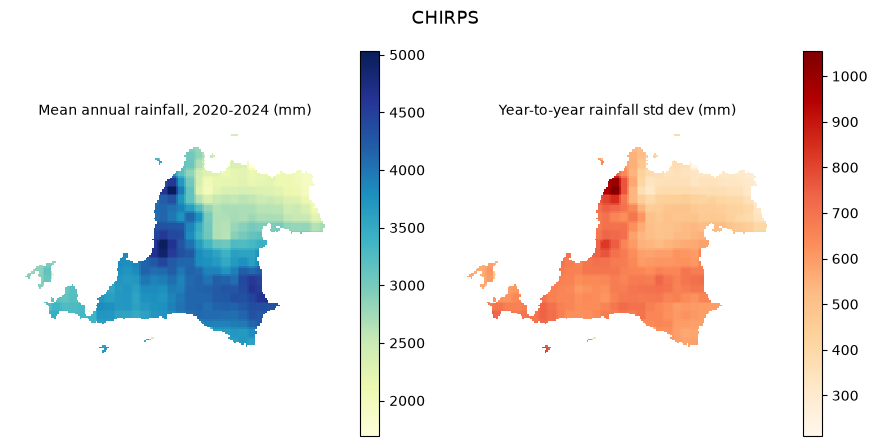

In [14]:
plot_columns(
    [
        ("chirps_annual_mean_mm", "Mean annual rainfall, 2020-2024 (mm)", "YlGnBu"),
        ("chirps_annual_std_mm", "Year-to-year rainfall std dev (mm)", "OrRd"),
    ],
    ncols=2, suptitle="CHIRPS",
)

### SoilGrids

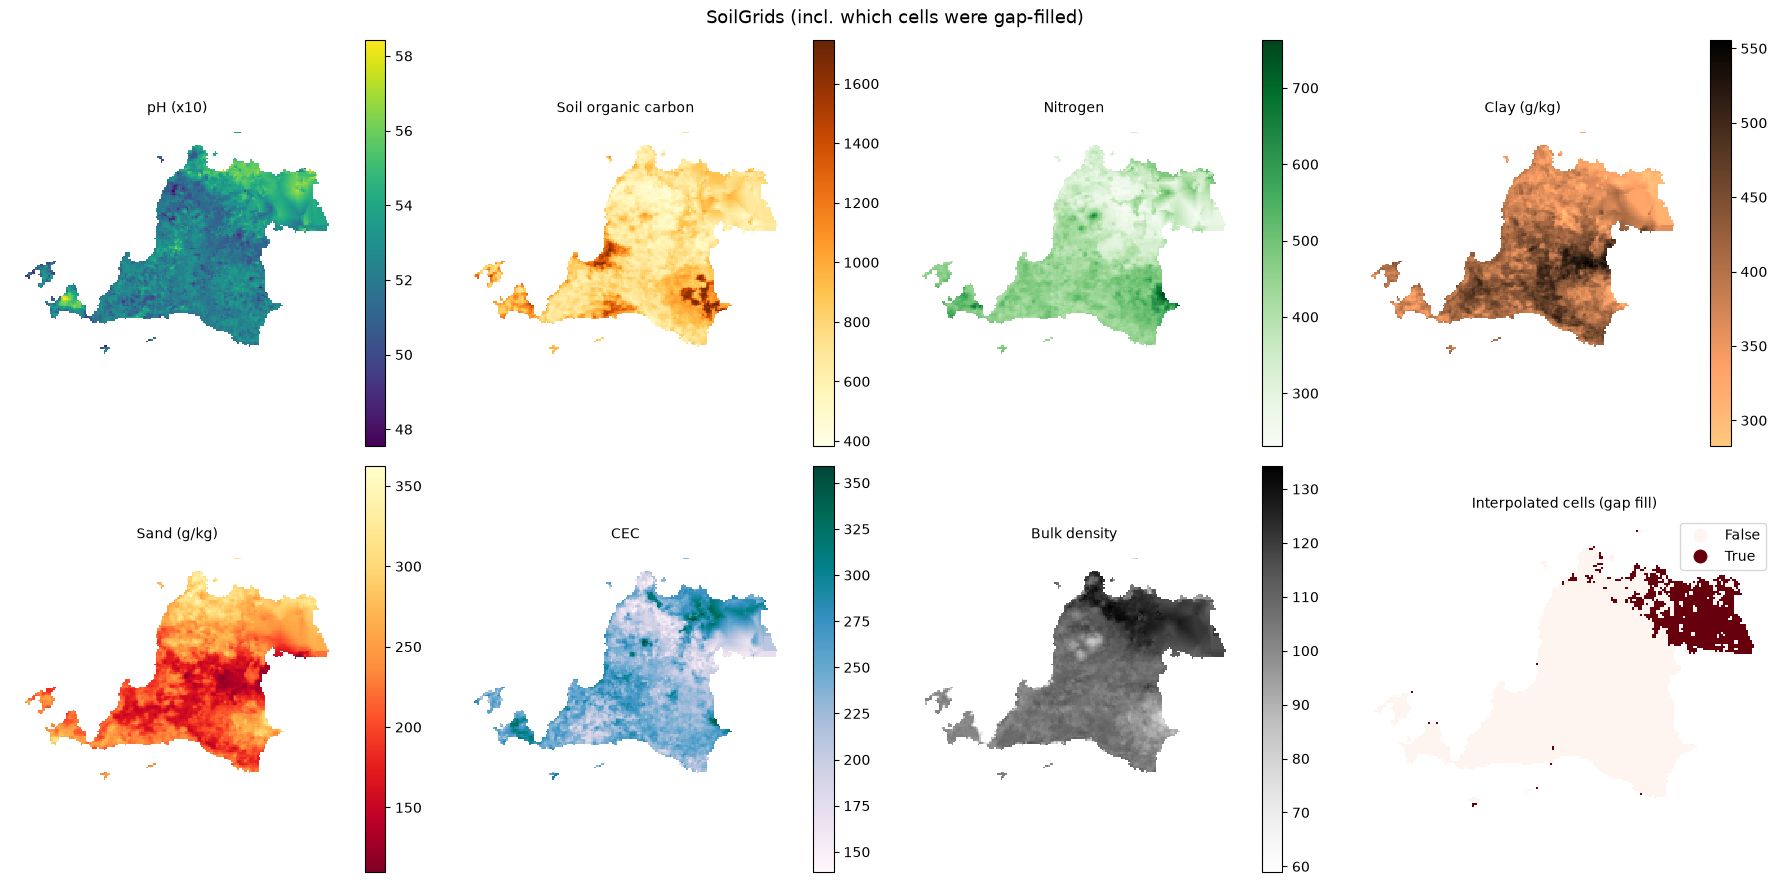

In [15]:
plot_columns(
    [
        ("soil_ph", "pH (x10)", "viridis"),
        ("soil_soc", "Soil organic carbon", "YlOrBr"),
        ("soil_nitrogen", "Nitrogen", "Greens"),
        ("soil_clay_pct", "Clay (g/kg)", "copper_r"),
        ("soil_sand_pct", "Sand (g/kg)", "YlOrRd_r"),
        ("soil_cec", "CEC", "PuBuGn"),
        ("soil_bulk_density", "Bulk density", "Greys"),
        ("soil_data_interpolated", "Interpolated cells (gap fill)", "Reds"),
    ],
    ncols=4, suptitle="SoilGrids (incl. which cells were gap-filled)",
)

## 12. SoilGrids before vs after interpolation - detail

`describe()` on the raw (pre-interpolation, still has NaNs) columns vs the final (post-interpolation, fully filled) columns, plus a before/after map for every property. These maps get **saved to a PNG file** instead of only `plt.show()` - some notebook/IDE themes recolor plot backgrounds on inline display, which makes a white/black availability map unreadable; the saved PNG file is unaffected by that.

In [16]:
raw_cols = [f"{c}_raw" for c in SOIL_COLS]
print("=== BEFORE interpolation (raw SoilGrids reads, NaN where the source had no data) ===")
display(features[raw_cols].describe().T)

print("\n=== AFTER interpolation (final columns used in the model - fully filled) ===")
display(features[SOIL_COLS].describe().T)

=== BEFORE interpolation (raw SoilGrids reads, NaN where the source had no data) ===


,count,mean,std,min,25%,50%,75%,max
soil_ph_raw,7894.0,52.444644,1.186544,47.560000,51.72,52.36,53.000000,58.440000
soil_soc_raw,7898.0,807.539827,216.540234,384.333333,669.54,758.86,892.601630,1748.160000
soil_nitrogen_raw,7894.0,419.419728,78.656615,231.333333,357.67,433.52,470.660000,763.320000
soil_clay_pct_raw,7894.0,409.748335,46.993464,283.000000,373.42,407.49,441.990000,555.960000
soil_sand_pct_raw,7894.0,217.633120,45.938632,110.000000,183.06,215.94,249.480000,362.600000
soil_cec_raw,7894.0,235.938297,32.519214,139.200000,216.28,236.96,256.085217,359.320000
soil_bulk_density_raw,7898.0,107.504528,8.937669,59.000000,103.04,107.08,111.040000,134.333333



=== AFTER interpolation (final columns used in the model - fully filled) ===


,count,mean,std,min,25%,50%,75%,max
soil_ph,9333.0,52.721407,1.335863,47.560000,51.850000,52.560000,53.440000,58.440000
soil_soc,9333.0,798.517776,203.705542,384.333333,674.319955,754.916667,873.840000,1748.160000
soil_nitrogen,9333.0,409.627874,79.157439,231.333333,343.333333,422.898551,464.606061,763.320000
soil_clay_pct,9333.0,400.676900,49.886561,283.000000,363.812500,397.440000,435.400000,555.960000
soil_sand_pct,9333.0,223.455056,46.410670,110.000000,188.200000,223.000000,257.520000,362.600000
soil_cec,9333.0,237.501650,34.795311,139.200000,215.200000,237.840000,259.320000,359.320000
soil_bulk_density,9333.0,109.292632,9.547693,59.000000,103.880000,108.200000,116.000000,134.333333


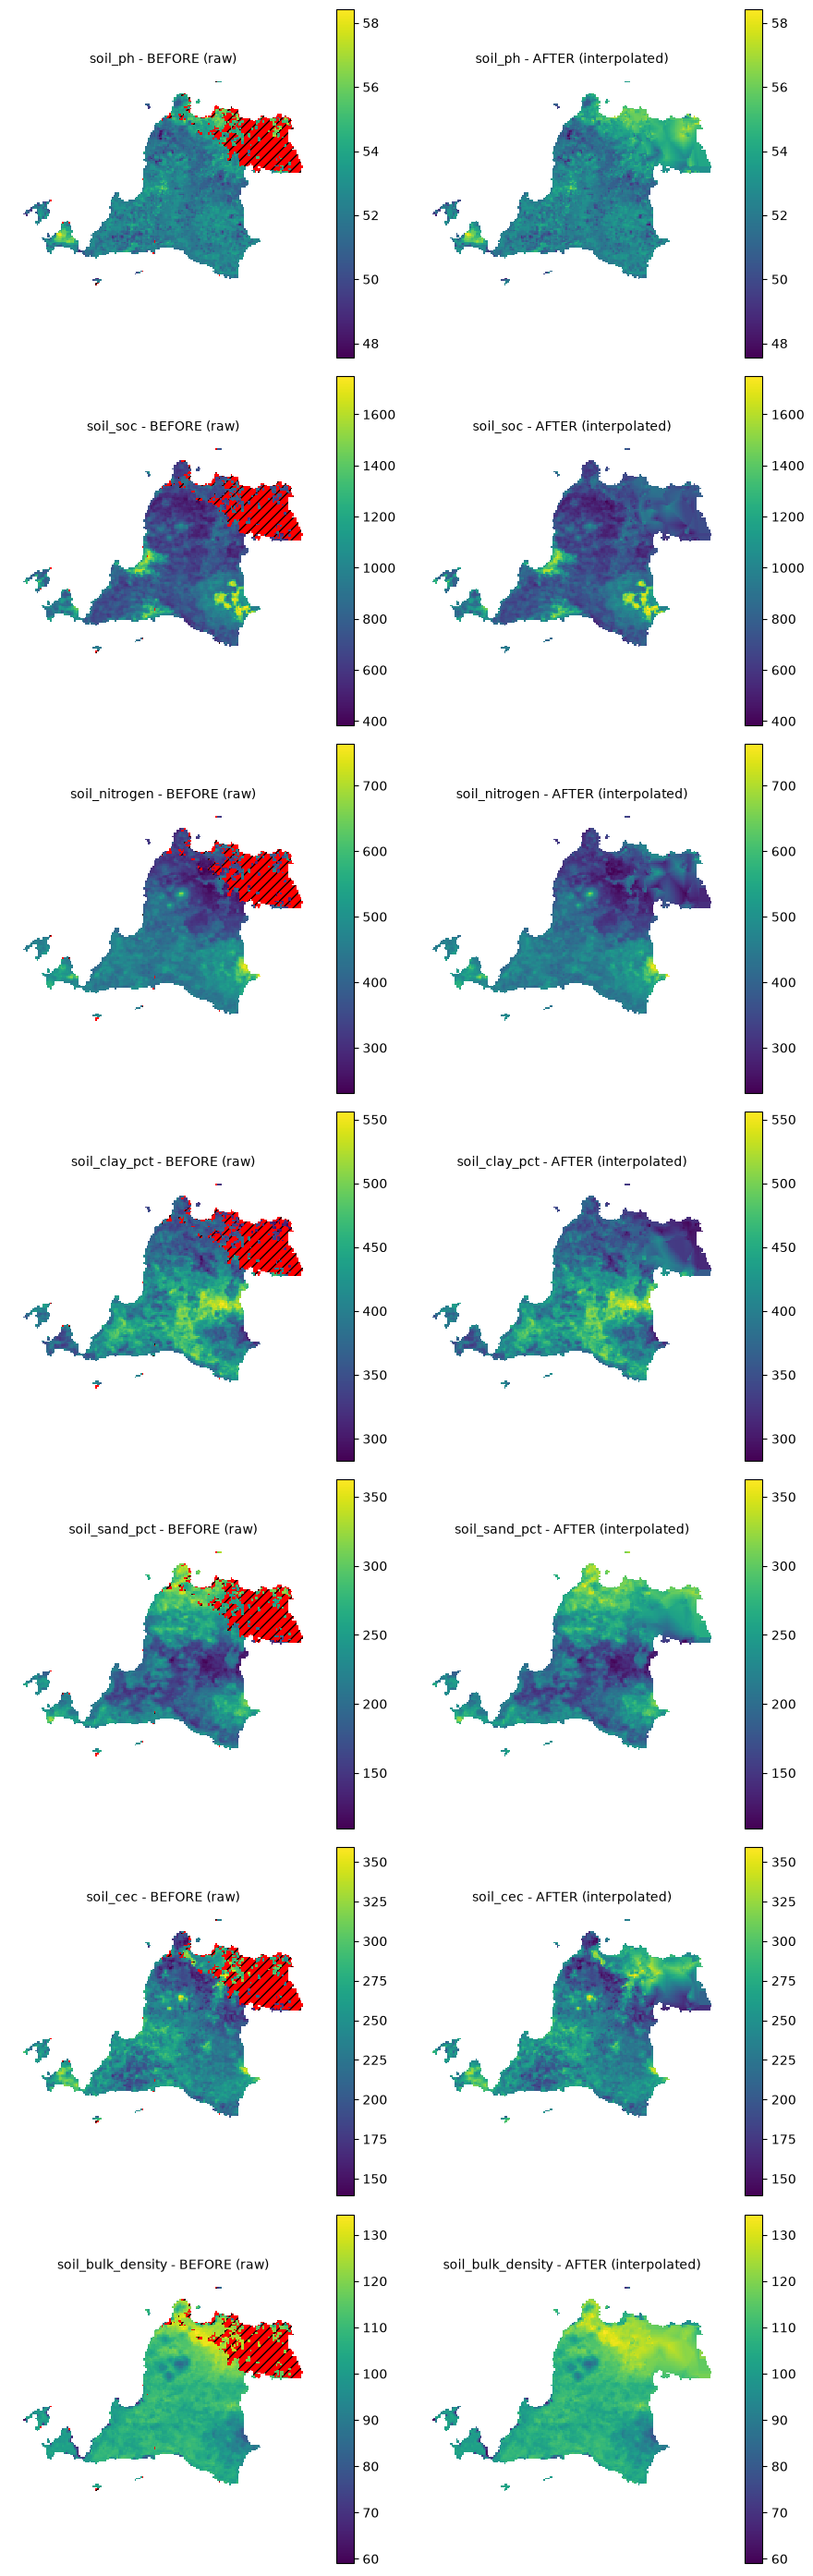

Saved to soilgrids_before_after.png - open that file directly if the colors above look wrong in this notebook viewer.


In [17]:
import matplotlib.pyplot as plt

merged_ba = grid.merge(features, on="grid_id", how="left")

fig, axes = plt.subplots(len(SOIL_COLS), 2, figsize=(9, 4 * len(SOIL_COLS)))

for row, col in enumerate(SOIL_COLS):
    raw_col = f"{col}_raw"

    ax_before, ax_after = axes[row]
    merged_ba.plot(
        column=raw_col, cmap="viridis", legend=True, ax=ax_before,
        missing_kwds={"color": "red", "hatch": "///", "label": "missing"},
    )
    ax_before.set_title(f"{col} - BEFORE (raw)", fontsize=10)
    ax_before.axis("off")

    merged_ba.plot(column=col, cmap="viridis", legend=True, ax=ax_after)
    ax_after.set_title(f"{col} - AFTER (interpolated)", fontsize=10)
    ax_after.axis("off")

plt.tight_layout()
out_path = "soilgrids_before_after.png"
plt.savefig(out_path, dpi=130, facecolor="white")
plt.show()
print(f"Saved to {out_path} - open that file directly if the colors above look wrong in this notebook viewer.")

### DEM

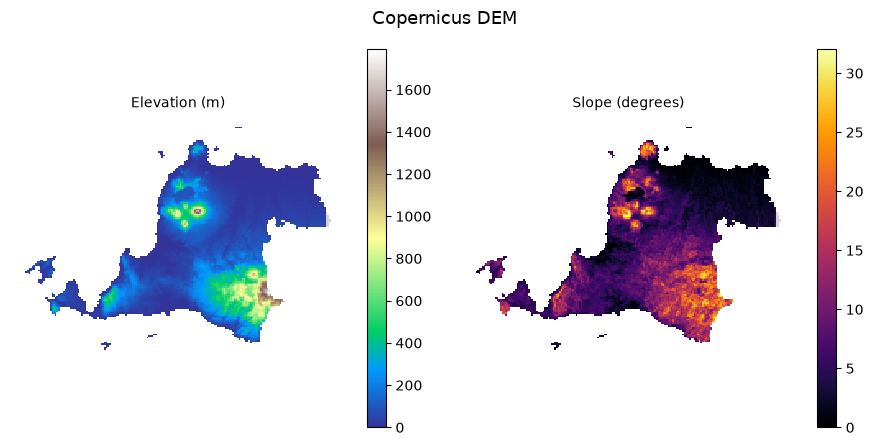

In [18]:
plot_columns(
    [
        ("elevation_mean_m", "Elevation (m)", "terrain"),
        ("slope_mean_deg", "Slope (degrees)", "inferno"),
    ],
    ncols=2, suptitle="Copernicus DEM",
)

### GAEZ v5 suitability class

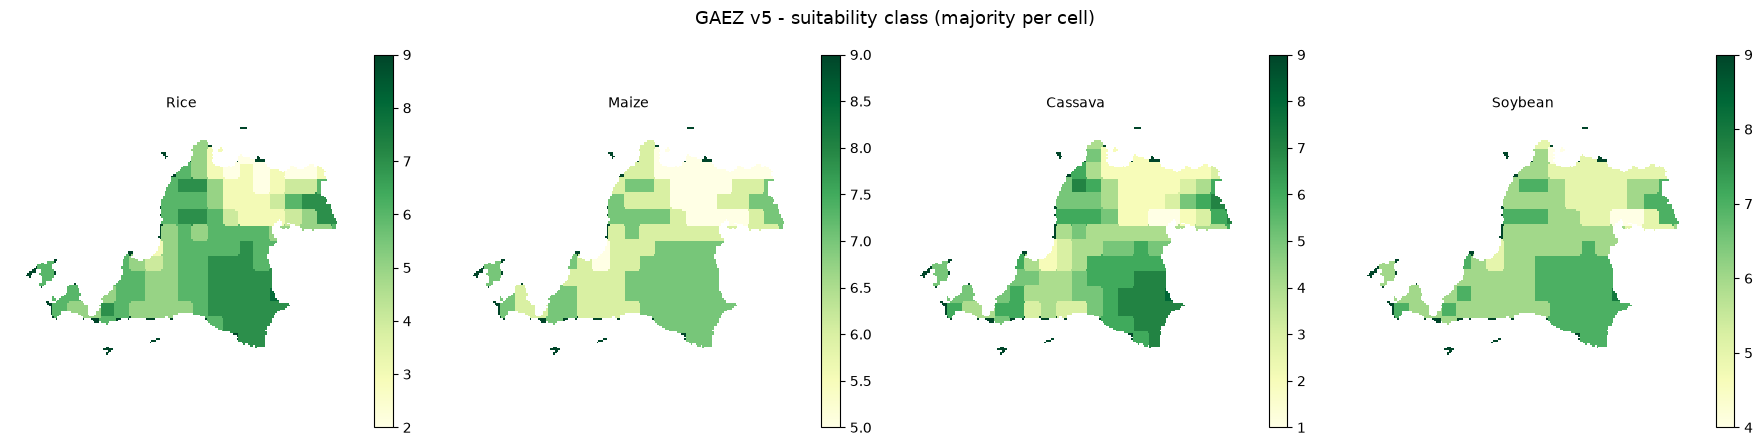

In [19]:
plot_columns(
    [
        ("gaez_class_rice", "Rice", "YlGn"),
        ("gaez_class_maize", "Maize", "YlGn"),
        ("gaez_class_cassava", "Cassava", "YlGn"),
        ("gaez_class_soybean", "Soybean", "YlGn"),
    ],
    ncols=4, suptitle="GAEZ v5 - suitability class (majority per cell)",
)

### ESA WorldCover

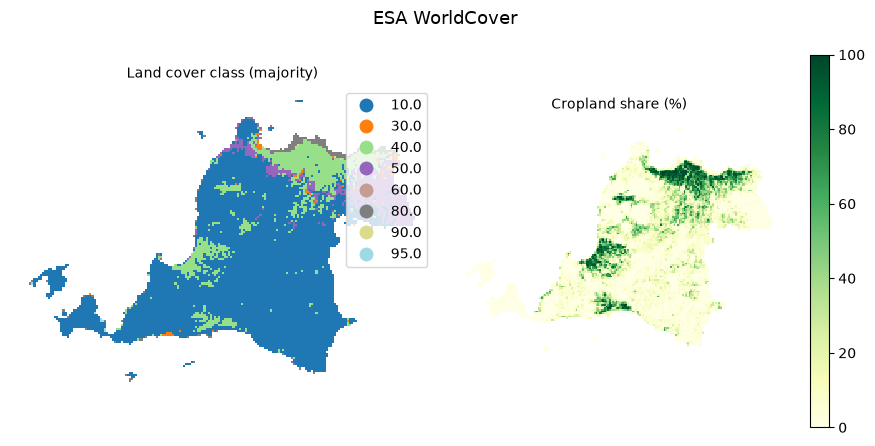

In [20]:
plot_columns(
    [
        ("landcover_majority", "Land cover class (majority)", "tab20", True),
        ("cropland_pct", "Cropland share (%)", "YlGn"),
    ],
    ncols=2, suptitle="ESA WorldCover",
)